# 02 · Análise de erros do modelo (XGBoost ajustado)

**Objetivo:** descobrir **onde** e **por que** o modelo erra, em vez de olhar só um número (RMSE).
Perguntas que vamos responder:
1. O erro é parecido em toda a vida do motor ou piora em alguma fase?
2. O modelo costuma **errar para mais** (achar que resta mais vida do que resta) ou **para menos**?
3. Há motores específicos muito piores que os outros?

**Regra de rigor:** a análise principal usa as previsões **fora da amostra da validação cruzada**
(cada motor é previsto por um modelo que nunca o viu), no treino. O conjunto de teste entra só no fim,
para **descrever**, e **não** para ajustar o modelo (se ajustássemos olhando o teste, ele deixaria de ser independente).

> Convenção: `erro = previsão - real`. **Positivo** = o modelo acha que resta MAIS vida do que resta de fato
> (perigoso na prática: a manutenção seria feita tarde demais). **Negativo** = acha que resta menos (manutenção antecipada).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

SRC = Path("..") / "src"
if SRC.exists():
    sys.path.insert(0, str(SRC.resolve()))

from cmapss.data import last_cycle_rows, load_test, load_train
from cmapss.features import DEFAULT_WINDOWS, add_rolling_features, feature_columns
from cmapss.train_baseline import usable_sensors

DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Melhor configuração encontrada no ajuste por validação cruzada (sorteio 18)
BEST = {
    "subsample": 0.7, "reg_lambda": 1, "n_estimators": 800, "min_child_weight": 3,
    "max_depth": 4, "learning_rate": 0.03, "colsample_bytree": 0.7,
}
SEED = 0


def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))

In [2]:
train = load_train(DATA_DIR)
test, rul_true = load_test(DATA_DIR)
sensors = usable_sensors(train)

train_f = add_rolling_features(train, sensors, DEFAULT_WINDOWS)
test_f = add_rolling_features(test, sensors, DEFAULT_WINDOWS)
cols = feature_columns(sensors, DEFAULT_WINDOWS)
x, y, groups = train_f[cols], train_f["RUL"], train_f["unit"]
print(len(cols), "variáveis |", train_f["unit"].nunique(), "motores de treino")

105 variáveis | 100 motores de treino


## 1. Previsões fora da amostra (validação cruzada por motor)
Cada motor é previsto por um modelo treinado **sem** ele. Assim o erro reflete o desempenho em motores novos.

In [3]:
oof = np.full(len(train_f), np.nan)
for tr, va in GroupKFold(n_splits=5).split(x, y, groups):
    model = XGBRegressor(n_jobs=-1, random_state=SEED, **BEST)
    model.fit(x.iloc[tr], y.iloc[tr])
    oof[va] = model.predict(x.iloc[va])

res = train_f[["unit", "cycle", "RUL"]].copy()
res["pred"] = oof
res["erro"] = res["pred"] - res["RUL"]
res["vida"] = res.groupby("unit")["cycle"].transform("max")
print("RMSE geral (fora da amostra):", round(rmse(res["erro"]), 2))
print("Viés médio (erro médio):", round(res["erro"].mean(), 2))

RMSE geral (fora da amostra): 15.24
Viés médio (erro médio): -0.68


## 2. O erro depende da fase da vida do motor?
Dividimos as linhas por **RUL real** (quanto falta para a falha). Lembre: acima de 125 a RUL foi limitada a 125
("saudável"), então a última faixa reúne todo o começo da vida.

In [4]:
bins = [-1, 10, 30, 60, 100, 125]
labels = ["0-10", "11-30", "31-60", "61-100", "101-125"]
res["faixa"] = pd.cut(res["RUL"], bins=bins, labels=labels)

tab = res.groupby("faixa", observed=True)["erro"].agg(
    rmse=lambda e: np.sqrt(np.mean(np.square(e))), vies="mean", n="size"
).round(2)
tab

,rmse,vies,n
faixa,,,
0-10,3.21,1.31,1100
11-30,6.88,2.26,2000
31-60,18.43,8.61,3000
61-100,20.84,9.80,4000
101-125,13.54,-8.07,10531


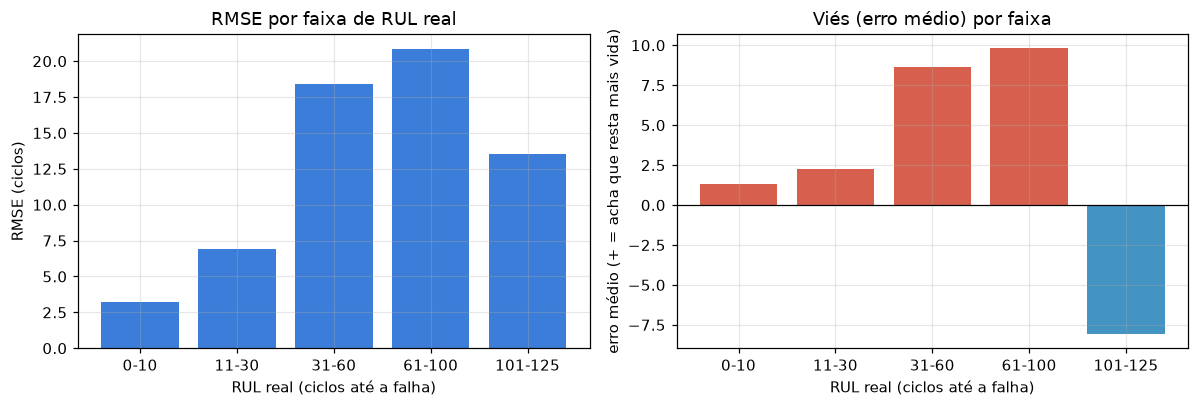

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(tab.index.astype(str), tab["rmse"], color="#3b7dd8")
axes[0].set_title("RMSE por faixa de RUL real")
axes[0].set_xlabel("RUL real (ciclos até a falha)")
axes[0].set_ylabel("RMSE (ciclos)")

cores = ["#d6604d" if v > 0 else "#4393c3" for v in tab["vies"]]
axes[1].bar(tab.index.astype(str), tab["vies"], color=cores)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Viés (erro médio) por faixa")
axes[1].set_xlabel("RUL real (ciclos até a falha)")
axes[1].set_ylabel("erro médio (+ = acha que resta mais vida)")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_erro_por_faixa_rul.png")
plt.show()

**Perguntas para você:**
- Em qual faixa o RMSE é maior? Faz sentido que perto da falha (faixas baixas) o erro seja **menor**, já que o desgaste está bem visível? 
O modelo tende a errar mais quanto mais longe da falha, (provavelmente por ser dificil a visualização do desgaste pelos sensores), quando perto da falha o erro tende a ser pouco
- O viés é positivo ou negativo? O modelo tende a ser otimista ou pessimista em cada fase?
positivo em geral, ou seja o modelo tende a ser mais otimista, menos na ultima faixa, mas mudamos ele propositalmente por convenção (nao ter um RUL maior q 125), mas caso nao fizessemos provavelmente o modelo erraria bastante
- Cuidado ao interpretar a faixa 101-125: ela é "fácil" por ser um valor limitado (cap), então tende a puxar o erro médio para baixo.

## 3. A trajetória de alguns motores
Comparamos, ao longo do tempo, a RUL **real** (limitada a 125) com a **prevista**. Escolhi motores de vida curta,
média e longa.

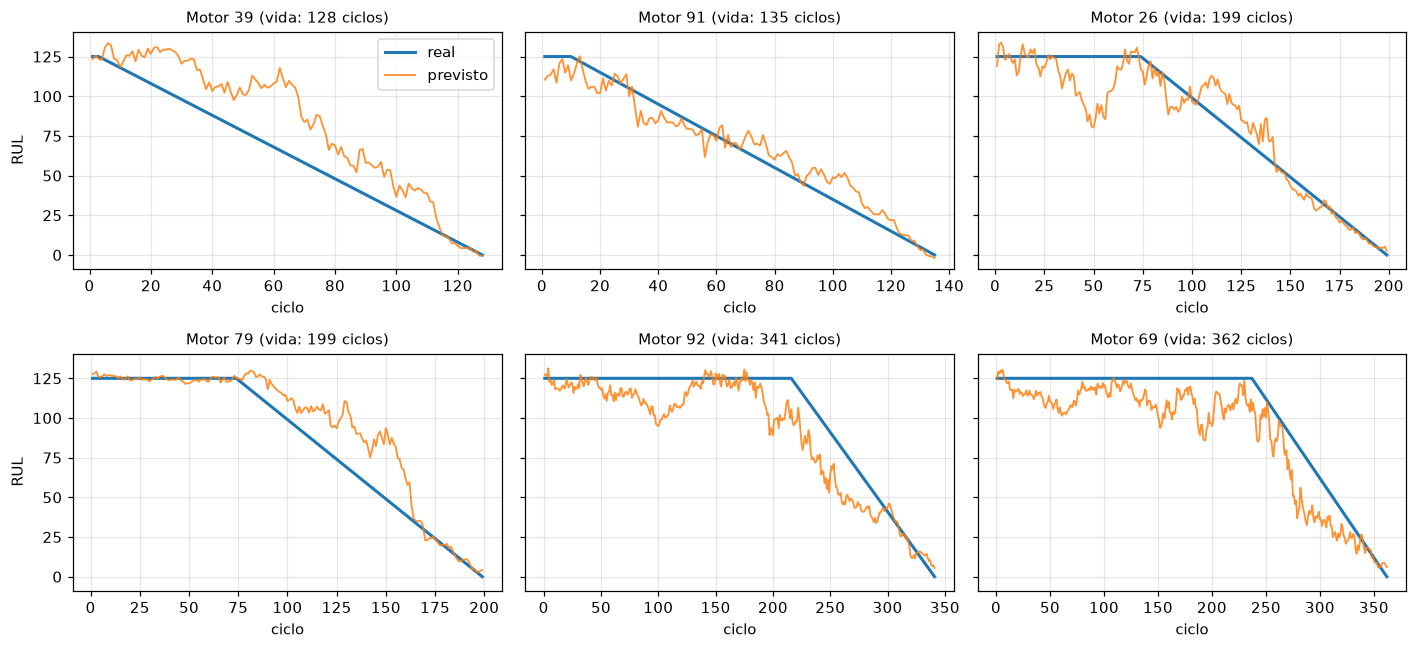

In [7]:
vidas = res.groupby("unit")["vida"].first().sort_values()
escolhidos = [vidas.index[0], vidas.index[1], vidas.index[len(vidas)//2 - 1], vidas.index[len(vidas)//2],
              vidas.index[-2], vidas.index[-1]]

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for ax, u in zip(axes.ravel(), escolhidos):
    d = res[res["unit"] == u]
    ax.plot(d["cycle"], d["RUL"], label="real", lw=2)
    ax.plot(d["cycle"], d["pred"], label="previsto", lw=1.2, alpha=0.85)
    ax.set_title(f"Motor {u} (vida: {int(d['vida'].iloc[0])} ciclos)", fontsize=10)
    ax.set_xlabel("ciclo")
axes[0, 0].set_ylabel("RUL")
axes[1, 0].set_ylabel("RUL")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "06_trajetorias_motores.png")
plt.show()

**Perguntas:** a linha prevista acompanha a real? Onde ela se afasta mais (no começo, no meio ou perto da falha)?
Os motores de vida curta e longa se comportam de forma diferente?

no meio é o mais dificil de prever tendo variações muito grandes mas em geral o modelo ainda está errando bastante

## 4. Há motores bem piores que os outros?
Calculamos o RMSE de cada motor e comparamos com quanto ele durou.

Pior 10 motores:


,rmse,vies,vida
unit,,,
24,27.06,17.71,147
57,26.53,18.39,137
90,25.45,19.12,154
28,24.88,17.25,165
66,24.04,-17.18,202
65,23.53,16.40,153
39,22.99,19.36,128
16,22.52,-18.26,209
77,22.04,11.59,154


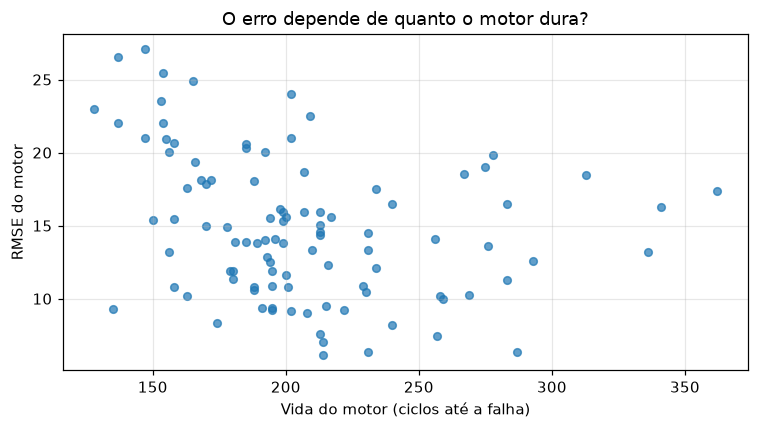

Correlação vida x RMSE: -0.29


In [8]:
por_motor = res.groupby("unit").agg(
    rmse=("erro", lambda e: np.sqrt(np.mean(np.square(e)))),
    vies=("erro", "mean"),
    vida=("vida", "first"),
).round(2)

print("Pior 10 motores:")
display(por_motor.sort_values("rmse", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(por_motor["vida"], por_motor["rmse"], s=25, alpha=0.7)
ax.set_xlabel("Vida do motor (ciclos até a falha)")
ax.set_ylabel("RMSE do motor")
ax.set_title("O erro depende de quanto o motor dura?")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_erro_por_motor.png")
plt.show()

print("Correlação vida x RMSE:", round(por_motor["vida"].corr(por_motor["rmse"]), 2))

**Pergunta:** os motores que duram pouco (ou muito) são mais difíceis? Uma correlação perto de 0 significa que
a vida total do motor não explica o erro.
os modelos que duram menos tendem a ter um erro maior no nosso modelo

## 5. No conjunto de teste (só para descrever)
Treinamos com todo o treino e prevemos o **último ciclo** de cada um dos 100 motores de teste. É a métrica
oficial do C-MAPSS. **Não ajuste o modelo olhando estes resultados.**

In [9]:
final = XGBRegressor(n_jobs=-1, random_state=SEED, **BEST)
final.fit(x, y)

test_last = last_cycle_rows(test_f)
t = pd.DataFrame({
    "unit": test_last["unit"].to_numpy(),
    "ciclos_observados": test_last["cycle"].to_numpy(),
    "real": rul_true,
    "pred": final.predict(test_last[cols]),
})
t["erro"] = t["pred"] - t["real"]


def nasa_score(d):
    # Métrica assimétrica do desafio C-MAPSS: pune mais prever vida DEMAIS (d > 0) do que de menos
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))


print("RMSE no teste:", round(rmse(t["erro"]), 2))
print("Score assimétrico (menor = melhor):", round(nasa_score(t["erro"].to_numpy()), 1))
print("Motores com erro > 0 (acha que resta MAIS vida):", f"{(t['erro'] > 0).mean():.0%}")

RMSE no teste: 16.16
Score assimétrico (menor = melhor): 645.9
Motores com erro > 0 (acha que resta MAIS vida): 59%


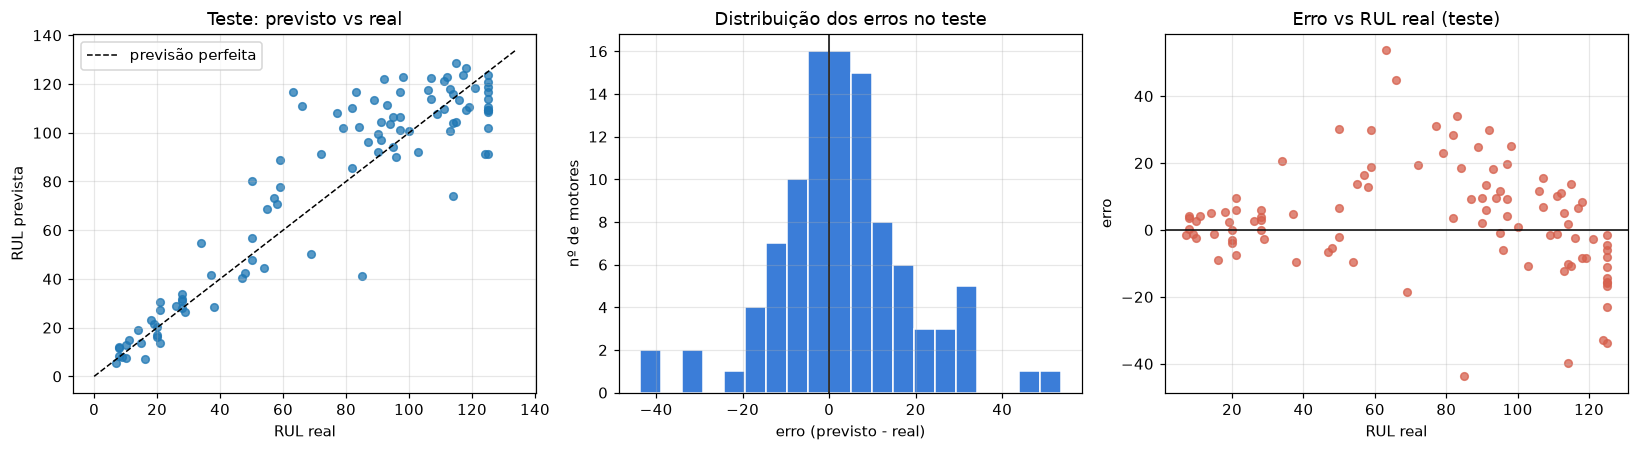

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

lim = [0, max(t["real"].max(), t["pred"].max()) + 5]
axes[0].scatter(t["real"], t["pred"], s=25, alpha=0.75)
axes[0].plot(lim, lim, "k--", lw=1, label="previsão perfeita")
axes[0].set_xlabel("RUL real")
axes[0].set_ylabel("RUL prevista")
axes[0].set_title("Teste: previsto vs real")
axes[0].legend()

axes[1].hist(t["erro"], bins=20, color="#3b7dd8", edgecolor="white")
axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("erro (previsto - real)")
axes[1].set_ylabel("nº de motores")
axes[1].set_title("Distribuição dos erros no teste")

axes[2].scatter(t["real"], t["erro"], s=25, alpha=0.75, color="#d6604d")
axes[2].axhline(0, color="k", lw=1)
axes[2].set_xlabel("RUL real")
axes[2].set_ylabel("erro")
axes[2].set_title("Erro vs RUL real (teste)")

fig.tight_layout()
fig.savefig(FIG_DIR / "08_teste_previsto_vs_real.png")
plt.show()

In [ ]:
print("10 piores motores do teste:")
display(t.reindex(t["erro"].abs().sort_values(ascending=False).index).head(10).round(1))

10 piores motores do teste:


,unit,ciclos_observados,real,pred,erro
78,79,101,63,116.599998,53.6
26,27,140,66,110.900002,44.9
92,93,244,85,41.200001,-43.8
44,45,152,114,74.099998,-39.9
14,15,76,83,116.900002,33.9
73,74,137,125,91.199997,-33.8
11,12,217,124,91.199997,-32.8
66,67,71,77,108.099998,31.1
71,72,131,50,80.000000,30.0
47,48,78,92,121.900002,29.9


**Perguntas:**
- Os pontos do gráfico da esquerda ficam perto da linha tracejada? Em qual região (RUL baixa ou alta) eles se afastam mais? mais na parte mediana pra alta
- O histograma é simétrico em torno de 0 ou pende para um lado? Se pender para o positivo, o modelo é "otimista" demais,
  o que é pior na prática de manutenção. (ele tende a ser mais otimista o que é pior na pratica para a manutenção)
- Os piores motores têm algo em comum (poucos ciclos observados, RUL real alta...)? sim todos tem RMSE alta e quase todos tem vida curta

## 6. O que aprendemos
- **Fase em que o erro é maior:** o RMSE cresce com a distância da falha até a zona de transição, de RUL real entre
  31 e 100 ciclos (RMSE 18,43 e 20,84), onde a degradação começa a aparecer nos sensores. Perto da falha o erro é
  baixo (3,21 na faixa 0-10 e 6,88 na faixa 11-30). Na faixa 101-125 ele cai para 13,54, em parte por efeito do
  cap em 125.
- **Viés (otimista ou pessimista):** positivo (superestima a vida restante) em todas as faixas até RUL 100:
  +1,31, +2,26, +8,61 e +9,80 ciclos, com maior viés em 31-100. O viés negativo na faixa 101-125 (−8,07) é em
  boa parte estrutural: a verdade fica no teto do cap e o modelo só consegue errar para baixo. Superestimar a
  vida é o erro mais custoso em manutenção, o que o score assimétrico do C-MAPSS penaliza.
- **Trajetória dos motores:** o modelo acompanha o formato da curva, mas detecta o início da degradação com atraso e
  tende à regressão à média: o viés médio por motor correlaciona-se negativamente com a vida do motor
  (r = −0,64 em todas as linhas e r = −0,65 só nas linhas com RUL ≤ 100, que excluem o efeito do cap; n = 100 motores).
  Motores de vida curta são superestimados e os de vida longa subestimados.
- **Motores mais difíceis:** os de vida curta (≈ 128 a 165 ciclos) têm os maiores RMSE por motor (≈ 20 a 27);
  parte dos de vida muito longa também é difícil (≈ 16 a 18).
- **No teste (último ciclo, RUL real limitada a 125):** RMSE 16,16 (semente 0; média de 5 sementes 15,96 ± 0,19),
  score assimétrico 645,9 e 59% dos motores com erro positivo (n = 100, margem de ≈ ±5 p.p.). O score é
  dominado por poucos erros grandes: um erro de +50 ciclos contribui com ≈ 147 pontos (e^(50/10) − 1).
  Contra a RUL real sem limite o RMSE é 17,25.
- **O que isso sugere tentar depois:** reduzir o atraso na detecção da degradação, com normalização de cada motor
  pelo seu estado inicial e variáveis de inclinação (tendência) dos sensores; e avaliar uma função de perda que
  penalize mais a superestimação da vida restante.